# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.16.0.dev2026091104
TensorFlow: 2.22.0-rc0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
# Problema: clasificar fotografías de tres medios de transporte con ruedas.
SEARCHES = {
    "bus": [
        "city bus on street",
        "public transport bus photo",
        "coach bus side view",
    ],
    "motorcycle": [
        "motorcycle on road",
        "motorbike parked street",
        "motorcycle rider side view",
    ],
    "bicycle": [
        "bicycle on street",
        "bike parked outdoors",
        "road bicycle photo",
    ],
}

SEARCHES

{'bus': ['city bus on street',
  'public transport bus photo',
  'coach bus side view'],
 'motorcycle': ['motorcycle on road',
  'motorbike parked street',
  'motorcycle rider side view'],
 'bicycle': ['bicycle on street',
  'bike parked outdoors',
  'road bicycle photo']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

### Respuesta — TODO 1

**Problema:** clasificar fotografías en 3 clases: `bus`, `motorcycle` y `bicycle`. Son clases visualmente distinguibles por tamaño, forma y número de ruedas, y no dependen de información que no se vea en la imagen.

**Términos de búsqueda:** tres por clase (ver el diccionario `SEARCHES`), en inglés porque suelen dar más resultados. Se mezclan términos de escena (calle, estacionado) y de vista (lateral) para variar fondos y ángulos.

**Hipótesis (¿qué características visuales usará el modelo?):**
- `bus`: silueta grande y rectangular, ventanas en fila, tamaño de la carrocería.
- `motorcycle`: motor y tanque visibles, dos ruedas gruesas, manubrio con retrovisores.
- `bicycle`: estructura de tubos delgados, ruedas finas con rayos, ausencia de motor.

**Imágenes incorrectas que espero encontrar:** ilustraciones y logos de empresas de transporte, fotos de interiores de un bus, ciclistas o motociclistas de cerca donde casi no se ve el vehículo, bicicletas eléctricas o scooters que se parecen a la clase vecina, y resultados de venta (fotos de catálogo con fondo blanco).

**Sesgo / *data leakage* posible al usar un buscador:**
- **Duplicados casi idénticos** (la misma foto en distintos tamaños o con otra compresión) pueden caer en train y en test; el hash SHA-256 solo elimina duplicados *exactos*. Eso infla el accuracy de test.
- **Sesgo de fondo/estilo:** los buses salen en carreteras urbanas, las bicicletas en parques o con fondo blanco de catálogo y las motos en estudios o pistas. El modelo podría aprender el fondo en lugar del vehículo.
- **Texto y marcas de agua** (logos de agencias, nombres de líneas de bus) que revelan la etiqueta.
- Los términos de búsqueda condicionan lo que se ve: el motor de búsqueda devuelve lo "típico", por lo que el modelo conocerá peor los casos atípicos.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bus ===
Buscando: 'city bus on street'
  Total guardadas hasta ahora: 33
Buscando: 'public transport bus photo'
  Total guardadas hasta ahora: 66
Buscando: 'coach bus side view'
  Total guardadas hasta ahora: 98

=== motorcycle ===
Buscando: 'motorcycle on road'
  Total guardadas hasta ahora: 34
Buscando: 'motorbike parked street'
  Total guardadas hasta ahora: 69
Buscando: 'motorcycle rider side view'
  Total guardadas hasta ahora: 104

=== bicycle ===
Buscando: 'bicycle on street'
  Total guardadas hasta ahora: 33
Buscando: 'bike parked outdoors'
  Total guardadas hasta ahora: 67
Buscando: 'road bicycle photo'
  Total guardadas hasta ahora: 102

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 102, 'bus': 98, 'motorcycle': 104}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

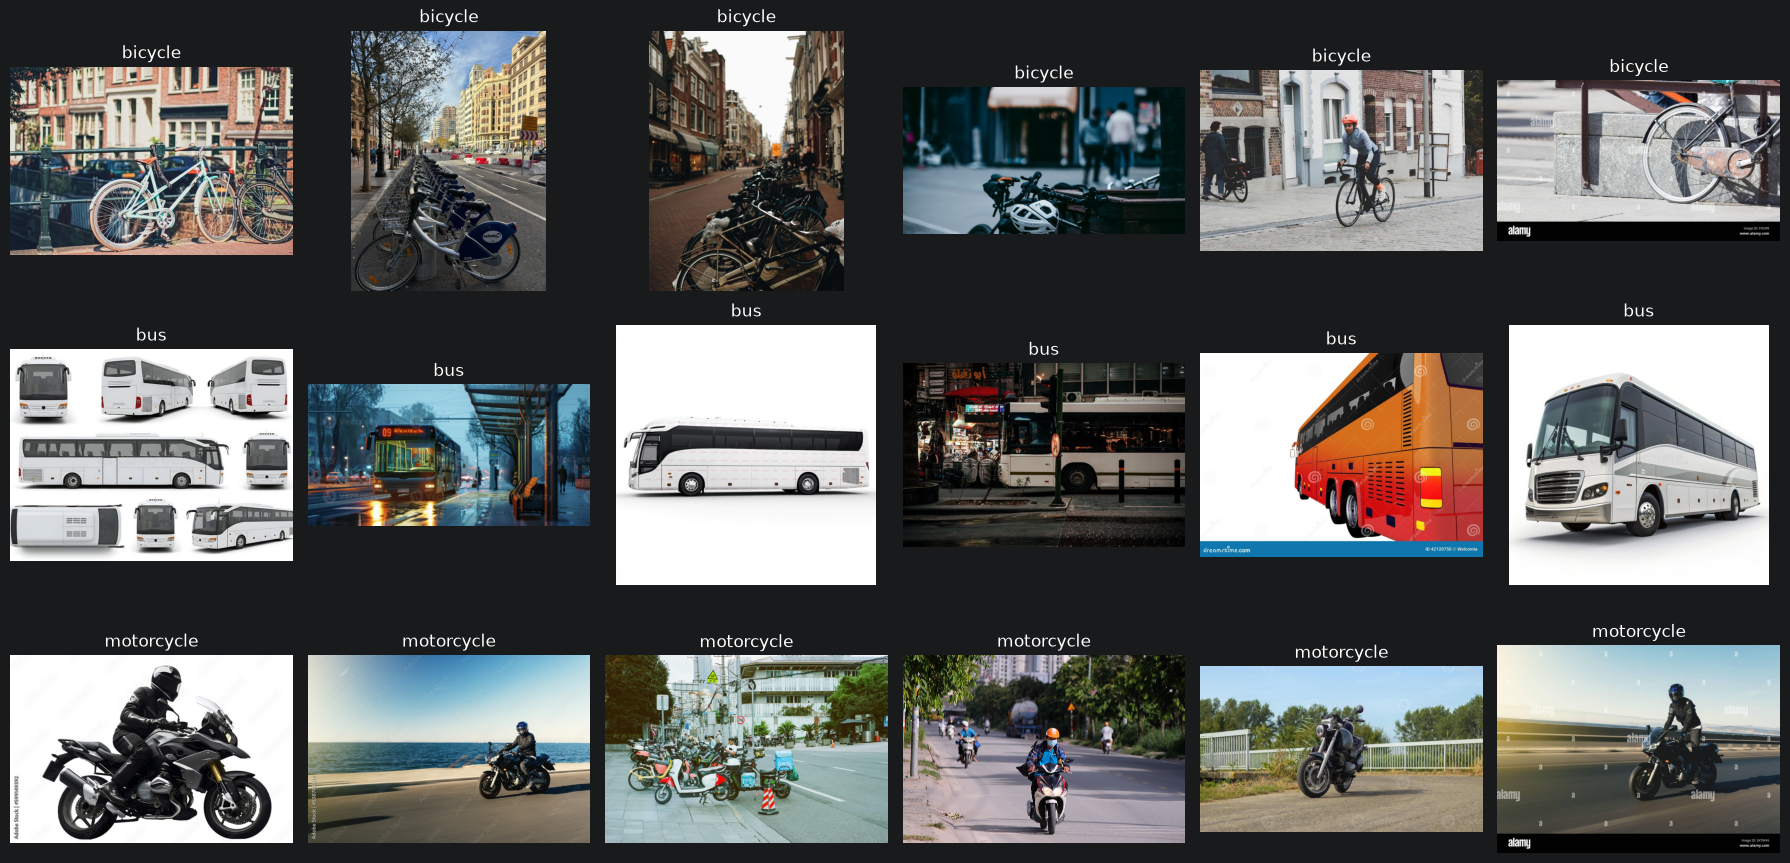

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

### Respuesta — checkpoint del dataset

La celda siguiente cuenta imágenes y balance por clase, y recoge cuántas imágenes inválidas eliminó la validación técnica. Después de inspeccionar visualmente las muestras (`show_random_images`), anota aquí lo observado. Lo que cabe esperar en este problema y qué hacer:

- **Problema de calidad más frecuente:** ilustraciones/logos y fotos de catálogo con fondo blanco, sobre todo en `bicycle` y `motorcycle`; y fotos donde la persona domina sobre el vehículo.
- **Acción:** borrar a mano los archivos claramente incorrectos de `data_raw/<clase>/` y, si una clase queda muy por debajo de las demás (≈100 imágenes útiles es el mínimo), mejorar *los términos de búsqueda* de esa clase y volver a ejecutar la descarga (ya evita duplicados exactos) en lugar de subir `max_results`.
- **Balance:** si las clases quedan muy desiguales, recortar la mayor al tamaño de la menor antes del split.

In [10]:
# Resumen del dataset después de la descarga y la limpieza
counts = count_images(RAW_DIR)
total = sum(counts.values())
print("Imágenes por clase:", counts, "| total:", total)
print("Proporción por clase:", {k: round(v / total, 3) for k, v in counts.items()})
print("Imágenes inválidas eliminadas por la validación técnica:", len(bad_files))
ratio = max(counts.values()) / max(1, min(counts.values()))
print(f"Razón clase mayor / clase menor: {ratio:.2f}",
      "(balanceado)" if ratio <= 1.3 else "(considera balancear o mejorar las búsquedas de la clase menor)")

Imágenes por clase: {'bicycle': 102, 'bus': 98, 'motorcycle': 104} | total: 304
Proporción por clase: {'bicycle': 0.336, 'bus': 0.322, 'motorcycle': 0.342}
Imágenes inválidas eliminadas por la validación técnica: 0
Razón clase mayor / clase menor: 1.06 (balanceado)


# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [11]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 71, 'bus': 68, 'motorcycle': 72}
validation {'bicycle': 15, 'bus': 14, 'motorcycle': 15}
test {'bicycle': 16, 'bus': 16, 'motorcycle': 17}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

### Respuesta

Porque cada vez que miramos el desempeño en test y **tomamos una decisión** con base en él (qué época, qué learning_rate, cuántas capas descongelar), el conjunto de prueba deja de ser datos "no vistos": su información se filtra hacia el modelo a través de nuestras decisiones. Con muchas decisiones y pocas imágenes, acabamos eligiendo la configuración que *por azar* acierta mejor en esas imágenes concretas (sobreajuste al conjunto de test). El resultado es una accuracy optimista que no se mantendrá con datos nuevos. Por eso las decisiones se toman con **validation**, y test se usa **una sola vez** al final para estimar el desempeño real.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 211 files belonging to 3 classes.
Found 44 files belonging to 3 classes.
Found 49 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**Predicción (antes de ejecutar):**
- Sí: con la base congelada solo se entrena la cabeza (≈ 3 840 parámetros con 3 clases: 1280·3 + 3), partiendo de características ya muy buenas de ImageNet, por lo que accuracy debería subir muy rápido (en 1–3 épocas) a valores altos para clases tan distintas.
- Señal de overfitting: val_loss deja de bajar o empieza a subir mientras loss de entrenamiento sigue bajando, y la brecha entre accuracy y val_accuracy se ensancha. Con pocas imágenes y data augmentation, es normal ver también val_accuracy ≥ accuracy en las primeras épocas, porque el entrenamiento usa augmentation y dropout y la validación no.

In [29]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10


C:\Users\Studio-PC\si3003-artificial-intelligence\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8957 - loss: 0.2930   WARNING:tensorflow:5 out of the last 57 calls to <function TensorFlowTrainer._make_function.<locals>.one_step_on_data at 0x00000213D4B2A770> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
7/7 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.8957 - loss: 0.2930 - val_accuracy: 0.9545 - val_loss: 0.2303
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 764ms/step - accuracy: 0.9573 - loss: 0.1040 - val_accuracy: 0.9545 

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

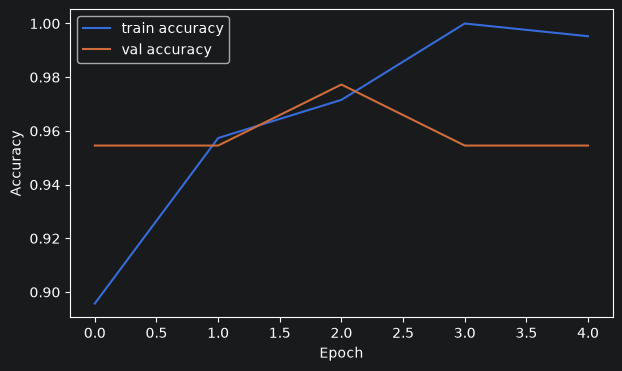

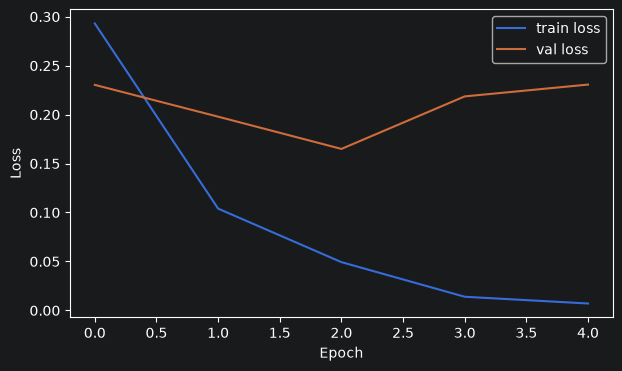

In [30]:
# Curvas de aprendizaje con el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [31]:
# Métricas finales del primer entrenamiento (backbone congelado), de la mejor época por val_loss
best_epoch = int(np.argmin(history.history["val_loss"]))
print(f"Mejor época (val_loss): {best_epoch + 1} de {len(history.history['loss'])}")
print(f"accuracy     = {history.history['accuracy'][best_epoch]:.4f}")
print(f"val_accuracy = {history.history['val_accuracy'][best_epoch]:.4f}")
print(f"loss         = {history.history['loss'][best_epoch]:.4f}")
print(f"val_loss     = {history.history['val_loss'][best_epoch]:.4f}")
gap = history.history['accuracy'][best_epoch] - history.history['val_accuracy'][best_epoch]
print(f"Brecha accuracy - val_accuracy: {gap:+.4f}")

Mejor época (val_loss): 3 de 5
accuracy     = 0.9716
val_accuracy = 0.9773
loss         = 0.0493
val_loss     = 0.1649
Brecha accuracy - val_accuracy: -0.0057


# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [17]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9796


              precision    recall  f1-score   support

     bicycle      1.000     0.938     0.968        16
         bus      1.000     1.000     1.000        16
  motorcycle      0.944     1.000     0.971        17

    accuracy                          0.980        49
   macro avg      0.981     0.979     0.980        49
weighted avg      0.981     0.980     0.980        49



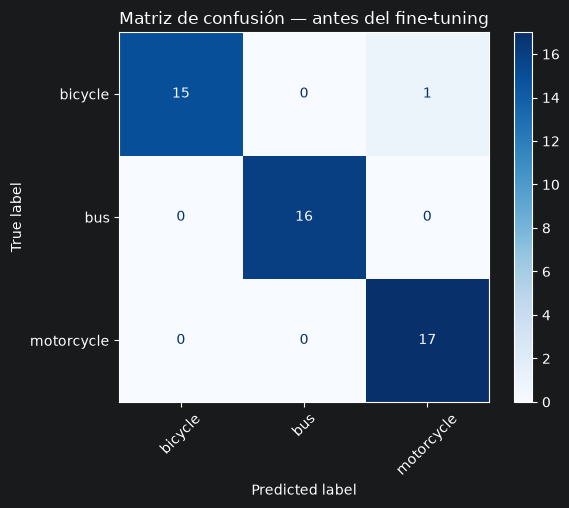

In [18]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

In [19]:
# Apoyo para el TODO 4: métricas por clase y principal confusión calculadas sobre las predicciones del primer modelo
from sklearn.metrics import precision_recall_fscore_support

prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
print(f"{'clase':<12}{'precision':>10}{'recall':>8}{'f1':>8}{'n':>5}")
for i, name in enumerate(class_names):
    print(f"{name:<12}{prec[i]:>10.3f}{rec[i]:>8.3f}{f1[i]:>8.3f}{support[i]:>5}")

best_c, worst_c = int(np.argmax(f1)), int(np.argmin(f1))
print(f"\n1) Mejor clase (F1): {class_names[best_c]} ({f1[best_c]:.3f})  |  peor: {class_names[worst_c]} ({f1[worst_c]:.3f})")

off = cm.copy(); np.fill_diagonal(off, 0)
if off.max() > 0:
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"2) Principal confusión: real = {class_names[i]} -> predicho = {class_names[j]} ({off[i, j]} imágenes)")
else:
    print("2) No hay confusiones en test.")

acc = (y_true == y_pred).mean()
print(f"3) Accuracy global = {acc:.3f}; recall por clase entre {rec.min():.3f} y {rec.max():.3f}"
      f" (diferencia {rec.max() - rec.min():.3f})")

clase        precision  recall      f1    n
bicycle          1.000   0.938   0.968   16
bus              1.000   1.000   1.000   16
motorcycle       0.944   1.000   0.971   17

1) Mejor clase (F1): bus (1.000)  |  peor: bicycle (0.968)
2) Principal confusión: real = bicycle -> predicho = motorcycle (1 imágenes)
3) Accuracy global = 0.980; recall por clase entre 0.938 y 1.000 (diferencia 0.062)


### Respuesta — TODO 4

Ejecuta la celda anterior: imprime las cifras que responden las preguntas 1–3. Cómo interpretarlas:

1. **Mejor clase:** la de mayor F1 en la tabla. Se espera que sea bus, por su forma y tamaño muy distintivos.
2. **Principal confusión:** el par con más imágenes fuera de la diagonal de la matriz. Lo más probable es bicycle ↔ motorcycle (comparten ruedas, manubrio y ciclistas/motociclistas de frente).
3. **¿La accuracy oculta algo?** Sí puede: la accuracy global es un promedio ponderado por el tamaño de cada clase. Si el recall de una clase es bastante menor que el de las otras (columna recall), una buena accuracy global tapa que esa clase falla más. Además, con un test de unas 20–30 imágenes por clase, un error cambia varios puntos del recall.
4. **Qué cambiaría primero en el dataset:** (a) eliminar duplicados casi idénticos y fotos que no sean del vehículo (logos, catálogo, interiores); (b) añadir más imágenes de la clase con peor recall, con términos de búsqueda distintos para variar fondos y ángulos; (c) balancear las clases. Mejorar los datos suele dar más que cambiar de arquitectura, porque el modelo ya es muy potente para este problema.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [20]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

### Respuesta — decisión de capas a descongelar

Se descongelan las últimas 20 capas de la base (valor de partida del enunciado), con BatchNormalization congelada y learning_rate=1e-5, 6 épocas máximas y EarlyStopping sobre val_loss. Razones: con un dataset de unos pocos cientos de imágenes, descongelar poco limita el riesgo de sobreajuste y de "olvidar" las características generales de ImageNet; las últimas capas son las más específicas y las que más conviene adaptar; y el learning_rate 100 veces menor que en la fase anterior evita destruir lo ya aprendido. La decisión debe confirmarse con validation: la celda siguiente al fine-tuning compara el mejor val_loss/val_accuracy antes y después; si val_loss no mejora, el valor correcto es descongelar menos (por ejemplo 10) y no más.

In [32]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=[early_stopping_ft],
)

Epoch 1/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9905 - loss: 0.0275 - val_accuracy: 0.9773 - val_loss: 0.1662
Epoch 2/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 807ms/step - accuracy: 0.9953 - loss: 0.0177 - val_accuracy: 0.9773 - val_loss: 0.1691
Epoch 3/6
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 825ms/step - accuracy: 1.0000 - loss: 0.0127 - val_accuracy: 0.9773 - val_loss: 0.1723


In [33]:
# Justificación con validation (no con test): mejor época antes y después del fine-tuning
def best_val(h):
    e = int(np.argmin(h.history["val_loss"]))
    return e + 1, h.history["val_loss"][e], h.history["val_accuracy"][e]

for name, h in [("Backbone congelado", history), (f"Fine-tuning ({N_UNFROZEN} capas)", history_ft)]:
    e, vl, va = best_val(h)
    print(f"{name:<28} mejor época={e}  val_loss={vl:.4f}  val_accuracy={va:.4f}")

improved = best_val(history_ft)[1] < best_val(history)[1]
print("\nEl fine-tuning", "mejoró" if improved else "NO mejoró", "val_loss respecto al modelo congelado.")

Backbone congelado           mejor época=3  val_loss=0.1649  val_accuracy=0.9773
Fine-tuning (20 capas)       mejor época=1  val_loss=0.1662  val_accuracy=0.9773

El fine-tuning NO mejoró val_loss respecto al modelo congelado.


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [23]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9796
Después del fine-tuning: 0.9796
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     0.938     0.968        16
         bus      1.000     1.000     1.000        16
  motorcycle      0.944     1.000     0.971        17

    accuracy                          0.980        49
   macro avg      0.981     0.979     0.980        49
weighted avg      0.981     0.980     0.980        49



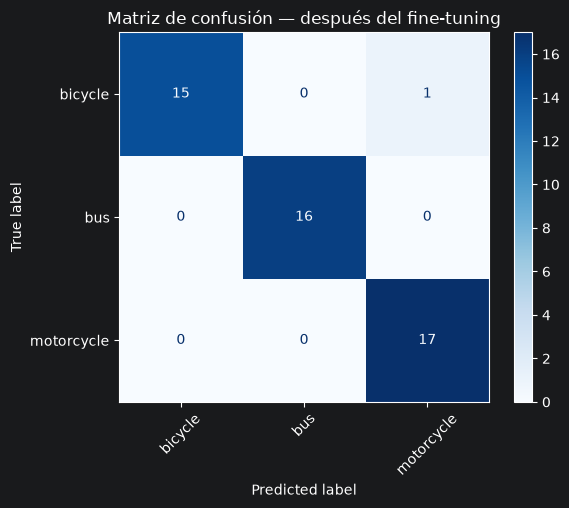

In [24]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

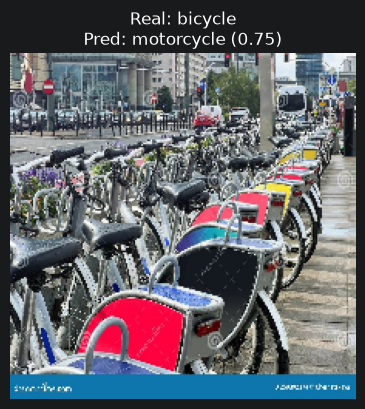

In [25]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

### Respuesta — TODO 6

**Los casos concretos de error los genera la celda siguiente** (5 errores con imagen, clase real, predicción y confianza). La *causa probable* y la mejora de cada uno solo se pueden decidir mirando la imagen; la tabla de abajo da las causas típicas de este problema para elegir la que corresponda a cada caso:

| Si ves... | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|
| Un ciclista o motociclista de cerca, vehículo apenas visible | Objeto pequeño / oclusión; la persona domina la imagen | Filtrar imágenes donde el vehículo ocupa poco; añadir plano completo |
| Bicicleta eléctrica, scooter o ciclomotor | Clase visualmente similar (frontera entre `bicycle` y `motorcycle`) | Más ejemplos de borde con etiqueta clara o definir mejor las clases |
| Dibujo, logo o foto de catálogo | Dato fuera de dominio / sesgo del dataset | Eliminarla en la limpieza semántica |
| Bus de interior o muy recortado | Imagen ambigua | Eliminar o reetiquetar |
| La etiqueta es claramente incorrecta | Etiqueta errónea del buscador | Corregir o borrar el archivo |
| Vehículo bien visible, confianza baja | Error razonable del modelo | Más datos y augmentation |

#### Conclusión (generada con tus cifras en la celda de código siguiente)

Errores en test tras el fine-tuning: 1 de 49


,real,prediccion,confianza,archivo
0,bicycle,motorcycle,0.746,dataset\test\bicycle\0035.jpg


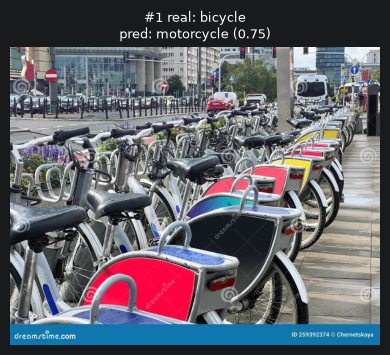

Solo hay 1 errores en test; completa el análisis con errores de validation (val_ds).


In [26]:
# TODO 6 — análisis de errores: 5 errores del modelo final (los de mayor confianza, que son los más informativos)
import pandas as pd
test_files = [p for c in class_names for p in sorted((SPLIT_DIR / "test" / c).glob("*.jpg"))]
assert len(test_files) == len(y_true_ft), "El orden de archivos no coincide con test_ds"

errors = pd.DataFrame({
    "archivo": [str(p) for p in test_files],
    "real": [class_names[i] for i in y_true_ft],
    "prediccion": [class_names[i] for i in y_pred_ft],
    "confianza": probabilities_ft.max(axis=1),
})
errors = errors[errors["real"] != errors["prediccion"]].sort_values("confianza", ascending=False)
print(f"Errores en test tras el fine-tuning: {len(errors)} de {len(test_files)}")
top5 = errors.head(5).reset_index(drop=True)
display(top5[["real", "prediccion", "confianza", "archivo"]].round(3)) if len(top5) else print("Sin errores.")

if len(top5):
    fig, axes = plt.subplots(1, len(top5), figsize=(4 * len(top5), 4))
    axes = np.atleast_1d(axes)
    for k, (ax, row) in enumerate(zip(axes, top5.itertuples()), start=1):
        ax.imshow(Image.open(row.archivo)); ax.axis("off")
        ax.set_title(f"#{k} real: {row.real}\npred: {row.prediccion} ({row.confianza:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()
    if len(errors) < 5:
        print(f"Solo hay {len(errors)} errores en test; completa el análisis con errores de validation (val_ds).")

In [27]:
# Conclusión con las cifras reales de la ejecución
from IPython.display import Markdown, display
d = test_acc_after - test_acc_before
e0, vl0, va0 = best_val(history)
e1, vl1, va1 = best_val(history_ft)
f1_ft = precision_recall_fscore_support(y_true_ft, y_pred_ft, labels=range(NUM_CLASSES), zero_division=0)[2]
cm_off = cm_ft.copy(); np.fill_diagonal(cm_off, 0)
conf = (f"la confusión más frecuente fue **{class_names[np.unravel_index(cm_off.argmax(), cm_off.shape)[0]]} → "
        f"{class_names[np.unravel_index(cm_off.argmax(), cm_off.shape)[1]]}** ({cm_off.max()} imágenes)") if cm_off.max() else "no hubo confusiones en test"
verdict = "ayudó" if d > 0 else ("no cambió" if d == 0 else "no ayudó")
display(Markdown(f"""
1. **Dataset:** construir los datos con un buscador exige limpieza semántica: no basta con que los archivos se abran. Los duplicados casi idénticos, los logos/catálogos y los fondos correlacionados con una clase son el principal riesgo de resultados optimistas.
2. **Principal problema de calidad:** imágenes que no son fotos reales del vehículo (ilustraciones, catálogo, planos con la persona dominante) y posible filtración entre splits por duplicados cercanos; {conf}.
3. **Cambio por el fine-tuning (test):** {test_acc_before:.3f} → {test_acc_after:.3f} (**{d:+.3f}**). En validación, `val_accuracy` pasó de {va0:.3f} a {va1:.3f} y `val_loss` de {vl0:.3f} a {vl1:.3f}. Mejor clase tras el ajuste: **{class_names[int(np.argmax(f1_ft))]}**.
4. **¿Ayudó?** El fine-tuning **{verdict}** en test. Con un test de {len(y_true_ft)} imágenes, una diferencia de una o dos imágenes ({1/len(y_true_ft):.3f} cada una) está dentro del ruido; la decisión de mantenerlo se apoya mejor en `val_loss` que en la accuracy de test. Si no mejora, es esperable: las características de ImageNet ya separan bien estas clases y hay pocos datos para adaptar más capas sin sobreajustar.
5. **Qué mejoraría primero:** los **datos** (más imágenes y más variadas por clase, sin duplicados ni errores de etiqueta), después el entrenamiento (augmentation, número de capas) y por último la arquitectura.
"""))


1. **Dataset:** construir los datos con un buscador exige limpieza semántica: no basta con que los archivos se abran. Los duplicados casi idénticos, los logos/catálogos y los fondos correlacionados con una clase son el principal riesgo de resultados optimistas.
2. **Principal problema de calidad:** imágenes que no son fotos reales del vehículo (ilustraciones, catálogo, planos con la persona dominante) y posible filtración entre splits por duplicados cercanos; la confusión más frecuente fue **bicycle → motorcycle** (1 imágenes).
3. **Cambio por el fine-tuning (test):** 0.980 → 0.980 (**+0.000**). En validación, `val_accuracy` pasó de 0.955 a 0.955 y `val_loss` de 0.197 a 0.187. Mejor clase tras el ajuste: **bus**.
4. **¿Ayudó?** El fine-tuning **no cambió** en test. Con un test de 49 imágenes, una diferencia de una o dos imágenes (0.020 cada una) está dentro del ruido; la decisión de mantenerlo se apoya mejor en `val_loss` que en la accuracy de test. Si no mejora, es esperable: las características de ImageNet ya separan bien estas clases y hay pocos datos para adaptar más capas sin sobreajustar.
5. **Qué mejoraría primero:** los **datos** (más imágenes y más variadas por clase, sin duplicados ni errores de etiqueta), después el entrenamiento (augmentation, número de capas) y por último la arquitectura.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [28]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

### Respuesta

| | **Feature extraction (base congelada)** | **Fine-tuning** | **CNN desde cero** |
|---|---|---|---|
| **De dónde viene el conocimiento inicial** | Los pesos de EfficientNetB0 aprendidos con millones de imágenes de ImageNet | Los mismos pesos de ImageNet, usados como punto de partida | Ninguno: pesos inicializados al azar |
| **Qué parámetros se aprenden** | Solo la cabeza nueva (`Dense` sobre `GlobalAveragePooling2D`, ≈ 3.8 mil parámetros); la base no cambia | La cabeza y las últimas capas descongeladas de la base (millones de parámetros, con `learning_rate` muy bajo) | Todos los parámetros de la red |
| **Datos necesarios** | Pocos (cientos) | Pocos a moderados | Muchos (decenas de miles o más) |
| **Riesgo** | Que las características generales no se ajusten bien al dominio | Sobreajuste y olvido de lo aprendido si se descongela mucho o el `learning_rate` es alto | Sobreajuste fuerte con pocos datos |

- **Feature extraction:** la base actúa como un extractor fijo de características (bordes, texturas, partes de objetos) y solo se entrena un clasificador sencillo sobre ellas. El conocimiento visual viene íntegramente de ImageNet.
- **Fine-tuning:** además de la cabeza, se permite que las capas más profundas y específicas se adapten al dominio nuevo. El conocimiento sigue viniendo de ImageNet, pero se refina con nuestros datos. Se usa un `learning_rate` bajo y se mantiene congelada `BatchNormalization` para no desestabilizar lo aprendido.
- **Desde cero:** la red debe aprender desde bordes hasta objetos completos solo con nuestras imágenes; con un dataset pequeño casi seguro se sobreajusta y rinde peor que reutilizar un modelo preentrenado.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |